# Rate, Term & Structure EDA

Scope matches each source script's original scope (all three FOIA vintages, unless noted) --
nothing here changes what was analyzed, only where it lives.


**What this notebook is asking.** Do a loan's own terms -- its interest rate, its term length,
whether it revolves, whether it's fixed or variable, who lent it and where -- carry real signal
about default risk, on their own? Sections build from pricing mechanics (rate vs. Prime, inflation-
adjusted amounts) -> structural features (term, revolver status, fixed/variable) -> geography and
lender concentration -> and close with the term=0 anomaly, which pulls together several of the
earlier threads (lender, geography, collateral, revolver status) to investigate one specific
data-quality question.

In [21]:
import sys
from pathlib import Path

def _find_project_root(marker="sector_eda.py"):
    """Walk up from the current working directory until we find the repo
    root (identified by sector_eda.py sitting next to src/) -- more robust
    than assuming cwd is any particular folder name, which breaks silently
    depending on how Jupyter was launched (plain `jupyter lab`, VS Code, etc.)."""
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(
        f"Could not locate the project root (looked for {marker!r} above {here}). "
        "Run this notebook from somewhere inside the pd-model-sba repo."
    )

PROJECT_ROOT = _find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src" / "data_prep"))

import load_sba
from sector_eda import load_clean_sector_df, ORDER # ORDER is a list consisting of datasets to be read;

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

OUT = str(PROJECT_ROOT / "outputs" / "figures")
pd.set_option("display.width", 160)

**What `load_clean_sector_df(name)` already did before you see this data.**
Every section below calls this one function -- it's not raw data, and knowing what already
happened to it matters for reading the sections that follow:

1. `load_sba.load_raw()` -- reads the FOIA CSV as-is.
2. `load_sba.normalize_categoricals()` -- strips whitespace/case noise from category-like columns
   (LoanStatus, ProcessingMethod, etc.) so `"PIF"` and `" pif "` aren't counted as different values.
3. `load_sba.clean_confirmed_issues()` -- **drops rows**, per settled decisions in `DECISIONS.md`:
   impossible date ordering (PaidInFullDate/ChargeOffDate before ApprovalDate), EXEMPT loans with a
   resolution date (contradicts what EXEMPT is supposed to mean), fully duplicated rows, non-US
   BankZip entries, implausible InitialInterestRate (>20%), implausible GrossApproval (<$1,000).
   This is why row counts here are lower than the raw file counts.
4. `naics_grouping` -- assigns each loan's NAICS code to one of the 20 Census sectors, then folds
   confirmed-sparse sectors into "Other".
5. `business_age_mapping` -- reconciles the pre-2018 fine-grained BusinessAge codes and the 2018+
   coarse codes into one consistent bucket scheme.
6. `load_sba.assign_target()` -- adds the plain `target` column used throughout this notebook:
   1=CHGOFF, 0=PIF, NA for CANCLD/EXEMPT/COMMIT. **Not** the vintage-normalized `target_60mo` used
   in Notebook 3 -- see the note on that distinction there.

None of this is exploratory -- it's the settled, decided cleanup, applied consistently everywhere
`load_clean_sector_df` is called. See `sector_eda.py` and `DECISIONS.md` for the full detail behind
each step.

## Data at a glance

Basic shape/missingness/duplicate check on the fully-cleaned, sector-assigned data everything below is built on -- context before diving into rate/term/structure specifics.

In [22]:
for name in ORDER:
    df = load_clean_sector_df(name)
    print(f"=== {name}: {df.shape[0]:,} rows x {df.shape[1]} columns ===")
    print(f"columns ({df.shape[1]}): {list(df.columns)}")
    print(f"duplicate rows: {df.duplicated().sum()}")
    missing = df.isna().mean().sort_values(ascending=False)
    missing = missing[missing > 0]
    print(f"columns with any missing values ({len(missing)}):")
    print((missing * 100).round(2).to_string())
    print()

=== 2000_2009: 689,939 rows x 46 columns ===
columns (46): ['AsOfDate', 'Program', 'LocationID', 'BorrName', 'BorrStreet', 'BorrCity', 'BorrState', 'BorrZip', 'BankName', 'BankFDICNumber', 'BankNCUANumber', 'BankStreet', 'BankCity', 'BankState', 'BankZip', 'GrossApproval', 'SBAGuaranteedApproval', 'ApprovalDate', 'ApprovalFY', 'FirstDisbursementDate', 'ProcessingMethod', 'InitialInterestRate', 'FixedorVariableInterestInd', 'TermInMonths', 'NaicsCode', 'NaicsDescription', 'FranchiseCode', 'FranchiseName', 'ProjectCounty', 'ProjectState', 'SBADistrictOffice', 'CongressionalDistrict', 'BusinessType', 'BusinessAge', 'LoanStatus', 'PaidInFullDate', 'ChargeOffDate', 'GrossChargeOffAmount', 'RevolverStatus', 'JobsSupported', 'CollateralInd', 'SoldSecMrktInd', 'NaicsSectorCode', 'NaicsSectorName', 'BusinessAgeBucket', 'target']
duplicate rows: 0
columns with any missing values (26):
BankNCUANumber                98.46
InitialInterestRate           94.70
FixedorVariableInterestInd    94.70
Fran

## Interest rate vs. Prime rate spread
One-off comparison: `InitialInterestRate` vs. Prime rate (FRED MPRIME) at `ApprovalDate`, across
all three FOIA files -- informs the implied-spread-over-Prime feature


In [24]:
MPRIME_PATH = str(load_sba._DATA_RAW / "MPRIME.csv")


def load_prime():
    prime = pd.read_csv(MPRIME_PATH, parse_dates=["observation_date"])
    prime["year_month"] = prime["observation_date"].dt.to_period("M")
    return prime.set_index("year_month")["MPRIME"]


prime = load_prime()
print(f"Prime rate series: {prime.index.min()} to {prime.index.max()}, {len(prime)} monthly points\n")

Prime rate series: 2000-01 to 2026-07, 319 monthly points



In [25]:
for name in ORDER:
    df = load_sba.load_raw(load_sba.FILES[name])

    # temp table only -- ApprovalDate + InitialInterestRate, joined to Prime
    # at the ApprovalDate's month. Doesn't touch/modify the loaded df.
    temp = df[["ApprovalDate", "InitialInterestRate"]].copy()
    temp["year_month"] = temp["ApprovalDate"].dt.to_period("M")
    temp["prime_at_approval"] = temp["year_month"].map(prime)
    temp["spread"] = temp["InitialInterestRate"] - temp["prime_at_approval"]

    n_total = len(temp)
    n_rate_missing = temp["InitialInterestRate"].isna().sum()
    n_prime_missing = temp["prime_at_approval"].isna().sum()  # ApprovalDate outside MPRIME.csv range
    spread = temp["spread"].dropna()

    print(f"=== {name} ===")
    print(f"rows: {n_total}  |  InitialInterestRate missing: {n_rate_missing} "
          f"({n_rate_missing/n_total*100:.1f}%)  |  ApprovalDate outside Prime series range: {n_prime_missing}")
    print(f"spread = InitialInterestRate - Prime, n={len(spread)}")
    print(spread.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
    print()

=== 2000_2009 ===
rows: 690333  |  InitialInterestRate missing: 653700 (94.7%)  |  ApprovalDate outside Prime series range: 10005
spread = InitialInterestRate - Prime, n=36633
count    36633.000000
mean         3.144159
std          1.288729
min         -3.250000
1%           0.459600
5%           1.500000
25%          2.260000
50%          2.750000
75%          4.000000
95%          5.500000
99%          6.500000
max         52.750000
Name: spread, dtype: float64

=== 2010_2019 ===
rows: 545751  |  InitialInterestRate missing: 0 (0.0%)  |  ApprovalDate outside Prime series range: 0
spread = InitialInterestRate - Prime, n=545751
count    545751.000000
mean          2.819407
std           1.459688
min          -5.500000
1%            0.000000
5%            0.990000
25%           2.000000
50%           2.700000
75%           3.260000
95%           6.000000
99%           6.500000
max           8.270000
Name: spread, dtype: float64

=== 2020_Curr ===
rows: 388338  |  InitialInterestRate mi

## GrossApproval: nominal vs. CPI-deflated
One-off comparison: nominal `GrossApproval` vs. CPI-deflated `GrossApproval` (deflated to today's
dollars using FRED CPIAUCNS), across all three FOIA files -- informs the "run both and compare"
decision logged in DECISIONS.md.

In [26]:
CPI_PATH = str(load_sba._DATA_RAW / "CPIAUCNS.csv")


def load_cpi():
    cpi = pd.read_csv(CPI_PATH, parse_dates=["observation_date"])
    cpi["year_month"] = cpi["observation_date"].dt.to_period("M")
    return cpi.set_index("year_month")["CPIAUCNS"]


cpi = load_cpi()
base_cpi = cpi.iloc[-1]  # most recent month = "today's dollars" base
print(f"CPI series: {cpi.index.min()} to {cpi.index.max()}, {len(cpi)} monthly points")
print(f"Base period (deflate TO this): {cpi.index[-1]}, CPIAUCNS={base_cpi:.3f}\n")

CPI series: 2000-01 to 2026-06, 318 monthly points
Base period (deflate TO this): 2026-06, CPIAUCNS=333.952



In [27]:
for name in ORDER:
    df = load_sba.load_raw(load_sba.FILES[name])

    temp = df[["ApprovalDate", "GrossApproval"]].copy()
    temp["year_month"] = temp["ApprovalDate"].dt.to_period("M")
    temp["cpi_at_approval"] = temp["year_month"].map(cpi)
    temp["deflator"] = base_cpi / temp["cpi_at_approval"]
    temp["GrossApproval_real"] = temp["GrossApproval"] * temp["deflator"]

    n_total = len(temp)
    n_cpi_missing = temp["cpi_at_approval"].isna().sum()  # ApprovalDate outside CPI series range

    print(f"=== {name} ===")
    print(f"rows: {n_total}  |  ApprovalDate outside CPI series range: {n_cpi_missing}")
    print(f"deflator range applied: {temp['deflator'].min():.3f} to {temp['deflator'].max():.3f}")
    print()
    print("nominal GrossApproval:")
    print(temp["GrossApproval"].describe(percentiles=[.25, .5, .75, .95]).apply(lambda x: f"{x:,.0f}"))
    print()
    print("CPI-deflated GrossApproval_real (today's dollars):")
    print(temp["GrossApproval_real"].describe(percentiles=[.25, .5, .75, .95]).apply(lambda x: f"{x:,.0f}"))
    print()
    pct_shift = (temp["GrossApproval_real"].median() / temp["GrossApproval"].median() - 1) * 100
    print(f"median shifts by {pct_shift:+.1f}% after deflation\n")

=== 2000_2009 ===
rows: 690333  |  ApprovalDate outside CPI series range: 10005
deflator range applied: 1.518 to 1.978

nominal GrossApproval:
count      690,333
mean       178,708
std        296,250
min             55
25%         25,000
50%         60,000
75%        182,000
95%        800,000
max      3,400,000
Name: GrossApproval, dtype: str

CPI-deflated GrossApproval_real (today's dollars):
count      680,328
mean       307,827
std        510,301
min            101
25%         41,996
50%         98,337
75%        310,974
95%      1,379,684
max      6,586,060
Name: GrossApproval_real, dtype: str

median shifts by +63.9% after deflation

=== 2010_2019 ===
rows: 545751  |  ApprovalDate outside CPI series range: 0
deflator range applied: 1.301 to 1.546

nominal GrossApproval:
count      545,751
mean       377,396
std        672,285
min          1,000
25%         40,000
50%        125,000
75%        360,000
95%      1,700,000
max      5,000,000
Name: GrossApproval, dtype: str

CPI-defla

## Rate vs. term vs. chargeoff rate
`InitialInterestRate` vs. `TermInMonths` vs. chargeoff rate -- does rate already "price in"
term-length risk, or does term carry independent signal once rate is controlled for?

In [28]:
frames = []
for name in ORDER:
    df = load_clean_sector_df(name)
    df["vintage_file"] = name
    frames.append(df)
pooled = pd.concat(frames, ignore_index=True)

resolved = pooled[pooled["LoanStatus"].isin(["PIF", "CHGOFF"])].copy()
rated = resolved.dropna(subset=["InitialInterestRate"])
print(f"resolved loans with a rate: {len(rated)} of {len(resolved)} resolved "
      f"({len(rated)/len(resolved)*100:.1f}%)")

# 1. raw correlation between rate and term
corr = rated["InitialInterestRate"].corr(rated["TermInMonths"])
print(f"\nPearson correlation, InitialInterestRate vs TermInMonths: {corr:.3f}")

# 2. does rate predict term-bucket? (median rate per term bucket)
term_bins = [0, 60, 84, 120, 180, 240, np.inf]
term_labels = ["<=60mo", "61-84mo", "85-120mo", "121-180mo", "181-240mo", "240mo+"]
rated["term_bucket"] = pd.cut(rated["TermInMonths"], bins=term_bins, labels=term_labels)
print("\nmedian InitialInterestRate by term bucket:")
print(rated.groupby("term_bucket")["InitialInterestRate"].agg(["median", "mean", "count"]))

FranchiseCode: nunique changed 5074 -> 5025 after whitespace/case normalization (hidden duplicate categories collapsed)
FranchiseCode: nunique changed 3691 -> 3598 after whitespace/case normalization (hidden duplicate categories collapsed)
resolved loans with a rate: 535789 of 1108062 resolved (48.4%)

Pearson correlation, InitialInterestRate vs TermInMonths: -0.181

median InitialInterestRate by term bucket:
             median      mean   count
term_bucket                          
<=60mo         6.00  6.506174  113584
61-84mo        6.55  6.968088  168736
85-120mo       6.01  6.882023  153999
121-180mo      6.00  6.156127   25483
181-240mo      5.90  5.758884   13745
240mo+         5.75  5.717069   59979


chargeoff rate % by term bucket (rows) x rate bucket (cols):
rate_bucket  <=5%  5-6%  6-7%  7-8%  8-10%  10%+
term_bucket                                     
<=60mo        7.4  16.5  18.6  25.0   32.9  35.2
61-84mo       1.9   5.4   5.4   7.5    4.8  13.7
85-120mo      1.8   4.9   8.3  11.1   11.9  15.9
121-180mo     2.4   3.8   2.7   2.6    4.9   6.2
181-240mo     2.8   7.2   4.4   5.6    7.3  16.7
240mo+        0.6   2.1   1.7   1.6    0.6   1.0

cell counts:
rate_bucket   <=5%   5-6%   6-7%   7-8%  8-10%   10%+
term_bucket                                          
<=60mo       19881  37942  22348  15534  13713   4159
61-84mo      18397  50013  29023  27307  38770   5222
85-120mo     13354  63554  25930  23390  13957  13800
121-180mo     3044  13482   4793   2737   1071    355
181-240mo     2602   8453   1777    698    191     24
240mo+       14632  32406   8570   3054   1017    299


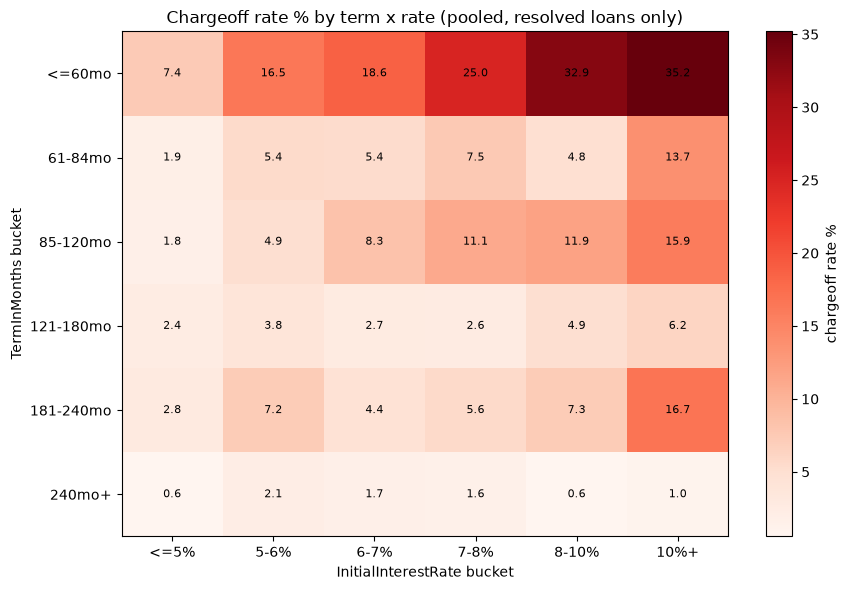

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/23_rate_x_term_x_chgoffrate.png


In [29]:
# 3. the actual question: does chargeoff rate vary by term WITHIN a rate
# bucket, and by rate WITHIN a term bucket? If rate already "prices in"
# term risk, term's effect should mostly disappear once rate is fixed.
rate_bins = [0, 5, 6, 7, 8, 10, np.inf]
rate_labels = ["<=5%", "5-6%", "6-7%", "7-8%", "8-10%", "10%+"]
rated["rate_bucket"] = pd.cut(rated["InitialInterestRate"], bins=rate_bins, labels=rate_labels)

pivot_rate = pd.crosstab(rated["term_bucket"], rated["rate_bucket"],
                          values=rated["target"], aggfunc="mean") * 100
pivot_n = pd.crosstab(rated["term_bucket"], rated["rate_bucket"])

print("chargeoff rate % by term bucket (rows) x rate bucket (cols):")
print(pivot_rate.round(1))
print("\ncell counts:")
print(pivot_n)

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(pivot_rate.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(len(pivot_rate.columns)))
ax.set_xticklabels(pivot_rate.columns)
ax.set_yticks(range(len(pivot_rate.index)))
ax.set_yticklabels(pivot_rate.index)
ax.set_xlabel("InitialInterestRate bucket")
ax.set_ylabel("TermInMonths bucket")
ax.set_title("Chargeoff rate % by term x rate (pooled, resolved loans only)")
for i in range(len(pivot_rate.index)):
    for j in range(len(pivot_rate.columns)):
        val = pivot_rate.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="chargeoff rate %")
fig.tight_layout()
fig.savefig(f"{OUT}/23_rate_x_term_x_chgoffrate.png", dpi=150)
plt.show()
print(f"saved {OUT}/23_rate_x_term_x_chgoffrate.png")

**Split by ProcessingMethod group.** Same term x rate x chargeoff-rate heatmap, split into
Express-type vs. Other `ProcessingMethod` -- tests whether the term effect (shorter term = higher
chargeoff) survives WITHIN each group, or whether it's fully explained by term just proxying for
Express-type/collateral status.

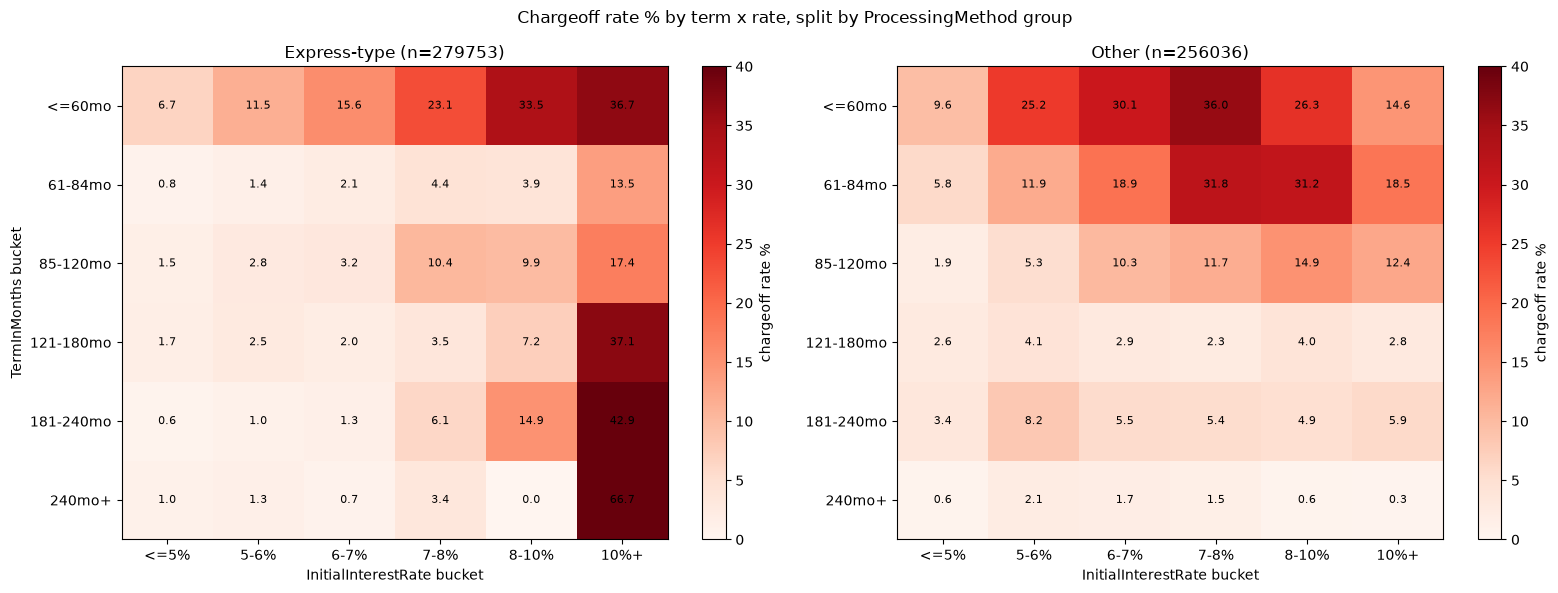

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/26_rate_x_term_by_methodgroup.png


In [30]:
EXPRESS_TYPE_METHODS = {"SBAEXPRESSPROGRAM", "COMMUNITYEXPRESS"}
rated["method_group"] = rated["ProcessingMethod"].apply(
    lambda m: "Express-type" if m in EXPRESS_TYPE_METHODS else "Other"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, group in zip(axes, ["Express-type", "Other"]):
    sub = rated[rated["method_group"] == group]
    pivot_rate = pd.crosstab(sub["term_bucket"], sub["rate_bucket"],
                              values=sub["target"], aggfunc="mean") * 100
    im = ax.imshow(pivot_rate.values, aspect="auto", cmap="Reds", vmin=0, vmax=40)
    ax.set_xticks(range(len(pivot_rate.columns)))
    ax.set_xticklabels(pivot_rate.columns)
    ax.set_yticks(range(len(pivot_rate.index)))
    ax.set_yticklabels(pivot_rate.index)
    ax.set_xlabel("InitialInterestRate bucket")
    ax.set_title(f"{group} (n={len(sub)})")
    for i in range(len(pivot_rate.index)):
        for j in range(len(pivot_rate.columns)):
            val = pivot_rate.values[i, j]
            if not np.isnan(val):
                ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="chargeoff rate %")
axes[0].set_ylabel("TermInMonths bucket")
fig.suptitle("Chargeoff rate % by term x rate, split by ProcessingMethod group")
fig.tight_layout()
fig.savefig(f"{OUT}/26_rate_x_term_by_methodgroup.png", dpi=150)
plt.show()
print(f"saved {OUT}/26_rate_x_term_by_methodgroup.png")

## Fixed vs. variable rate
`FixedorVariableInterestInd` vs. `ProcessingMethod`, chargeoff rate, and term. Variable-rate loans
are far more common than fixed across all three files -- this checks whether that split also
carries a risk/structural signal.

In [31]:
for name in ORDER:
    df = load_clean_sector_df(name)
    print(f"\n{'='*25} {name} {'='*25}")

    print("\nFixedorVariableInterestInd overall mix:")
    print(df["FixedorVariableInterestInd"].value_counts(dropna=False))

    resolved = df[df["LoanStatus"].isin(["PIF", "CHGOFF"])]
    print("\nchargeoff rate by Fixed/Variable (resolved only):")
    g = resolved.groupby("FixedorVariableInterestInd")["target"]
    print(pd.DataFrame({"n_resolved": g.size(), "chgoff_rate_pct": (g.mean() * 100).round(2)}))

    print("\nmedian/mean TermInMonths by Fixed/Variable:")
    print(df.groupby("FixedorVariableInterestInd")["TermInMonths"].agg(["median", "mean"]).round(1))

    print("\nFixed/Variable mix by top 8 ProcessingMethod (by volume):")
    top_methods = df["ProcessingMethod"].value_counts().head(8).index
    ct = pd.crosstab(df.loc[df["ProcessingMethod"].isin(top_methods), "ProcessingMethod"],
                      df.loc[df["ProcessingMethod"].isin(top_methods), "FixedorVariableInterestInd"],
                      normalize="index") * 100
    print(ct.round(1))


========================= 2000_2009 =========================

FixedorVariableInterestInd overall mix:
FixedorVariableInterestInd
<NA>    653355
V        32045
F         4539
Name: count, dtype: Int64

chargeoff rate by Fixed/Variable (resolved only):
                            n_resolved  chgoff_rate_pct
FixedorVariableInterestInd                             
F                                 3915             8.12
V                                28243            15.88

median/mean TermInMonths by Fixed/Variable:
                            median   mean
FixedorVariableInterestInd               
F                             60.0   80.0
V                             84.0  107.7

Fixed/Variable mix by top 8 ProcessingMethod (by volume):
FixedorVariableInterestInd     F      V
ProcessingMethod                       
7AGENERAL                    8.5   91.5
CERTIFIEDLENDERSPROGRAM      2.2   97.8
COMMUNITYEXPRESS             3.3   96.7
INTERNATIONALTRADELOANS      0.0  100.0
PATRIOTEXPR

## RevolverStatus profile
Chargeoff rate, collateral, guarantee %, loan size, fixed/variable mix -- for revolving vs. term
loans, and cross-checked against term=0.

In [32]:
frames = [load_clean_sector_df(n) for n in ORDER]
pooled = pd.concat(frames, ignore_index=True)
resolved = pooled[pooled["LoanStatus"].isin(["PIF", "CHGOFF"])].copy()
resolved["guarantee_pct"] = resolved["SBAGuaranteedApproval"] / resolved["GrossApproval"] * 100
resolved["is_term_zero"] = resolved["TermInMonths"] == 0

# % of dataset that is revolver
revolver_share = pooled["RevolverStatus"].value_counts(normalize=True) * 100
print("% of full (not just resolved) dataset by RevolverStatus:")
print(revolver_share.round(2))

FranchiseCode: nunique changed 5074 -> 5025 after whitespace/case normalization (hidden duplicate categories collapsed)
FranchiseCode: nunique changed 3691 -> 3598 after whitespace/case normalization (hidden duplicate categories collapsed)
% of full (not just resolved) dataset by RevolverStatus:
RevolverStatus
N    70.78
Y    29.22
Name: proportion, dtype: Float64


In [38]:
# high-level profile, revolver vs term loans
profile = resolved.groupby("RevolverStatus").agg(
    n=("target", "size"),
    chgoff_rate_pct=("target", lambda s: round(s.mean() * 100, 1)),
    pct_collateral_Y=("CollateralInd", lambda s: round((s == "Y").mean() * 100, 1)),
    avg_guarantee_pct=("guarantee_pct", lambda s: round(s.mean(), 1)),
    median_GrossApproval=("GrossApproval", "median"),
    pct_variable_rate=("FixedorVariableInterestInd", lambda s: round((s == "V").mean() * 100, 1)),
)
print("profile by RevolverStatus (resolved loans):")
print(profile)

profile by RevolverStatus (resolved loans):
                     n  chgoff_rate_pct  pct_collateral_Y  avg_guarantee_pct  median_GrossApproval  pct_variable_rate
RevolverStatus                                                                                                       
N               768223             16.2              44.7               69.7              140000.0               70.4
Y               339839             18.0              32.4               51.3               31000.0               97.7


term=0 x RevolverStatus, chargeoff rate + median GrossApproval jointly:
                                  n  chgoff_rate_pct  median_GrossApproval
is_term_zero RevolverStatus                                               
False        N               767567             16.1              140000.0
             Y               339356             17.9               31000.0
True         N                  656             73.6               60000.0
             Y                  483             81.4               31000.0


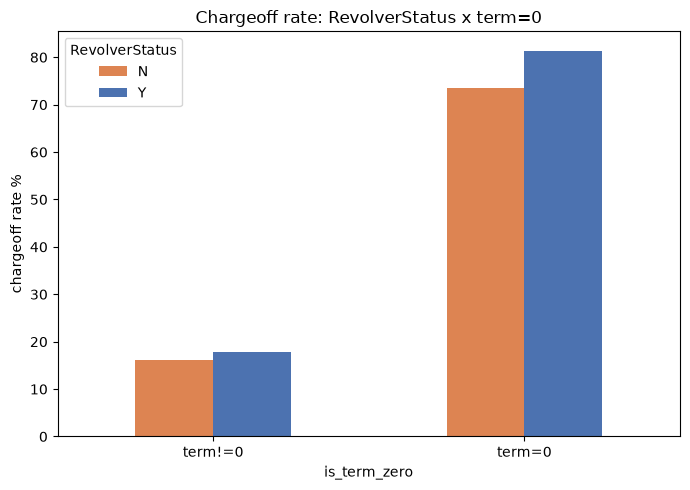

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/35_revolver_x_termzero_chgoffrate.png


In [39]:
# RevolverStatus x GrossApproval x term=0 x chargeoff, jointly
joint = resolved.groupby(["is_term_zero", "RevolverStatus"]).agg(
    n=("target", "size"),
    chgoff_rate_pct=("target", lambda s: round(s.mean() * 100, 1)),
    median_GrossApproval=("GrossApproval", "median"),
)
print("term=0 x RevolverStatus, chargeoff rate + median GrossApproval jointly:")
print(joint)

fig, ax = plt.subplots(figsize=(7, 5))
joint["chgoff_rate_pct"].unstack("RevolverStatus").plot(kind="bar", ax=ax, color=["#DD8452", "#4C72B0"])
ax.set_xticklabels(["term!=0", "term=0"], rotation=0)
ax.set_ylabel("chargeoff rate %")
ax.set_title("Chargeoff rate: RevolverStatus x term=0")
fig.tight_layout()
fig.savefig(f"{OUT}/35_revolver_x_termzero_chgoffrate.png", dpi=150)
plt.show()
print(f"saved {OUT}/35_revolver_x_termzero_chgoffrate.png")

## Geography risk tiers & lender concentration
Geography risk-tier feature (zip-3 level, event-count floor + quantile bins) and lender
concentration (`LocationID`, top-N by volume). `build_geo_tiers()` defined here is reused
directly below in the term=0 cross-check (no import needed now that both live in one notebook).

zip-3 units with >=30 events: 879 (out of 974 total)

risk tier summary (min chgoff_rate_pct, max, n zip3 units, total loans):
            min_rate   max_rate  n_zip3  total_loans
risk_tier                                           
A           1.639344  12.053433     220       186776
B          12.057667  15.000000     220       278674
C          15.025907  18.737673     219       278010
D          18.746159  49.275362     220       364110


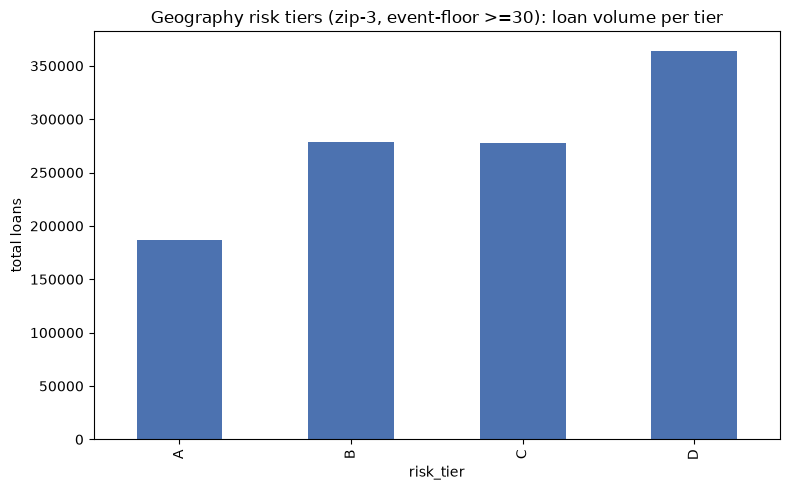

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/29_geo_risk_tiers.png

coverage: 100.0% of resolved loans fall in a zip3 with enough events to be tiered


In [40]:
def build_geo_tiers(resolved, min_events=30, n_tiers=4):
    """zip-3 level chargeoff rate, event-floor filtered, quantile-binned into tiers A (lowest risk) .. D (highest)."""
    resolved = resolved.copy()
    resolved["zip3"] = resolved["BorrZip"].str[:3]
    g = resolved.groupby("zip3")["target"]
    table = pd.DataFrame({"n": g.size(), "chgoff_rate_pct": g.mean() * 100})
    table = table[table["n"] >= min_events]

    labels = [chr(65 + i) for i in range(n_tiers)]  # A, B, C, D...
    table["risk_tier"] = pd.qcut(table["chgoff_rate_pct"], q=n_tiers, labels=labels)
    return table


geo = build_geo_tiers(resolved, min_events=30, n_tiers=4)
print(f"zip-3 units with >=30 events: {len(geo)} (out of {resolved['BorrZip'].str[:3].nunique()} total)")
print("\nrisk tier summary (min chgoff_rate_pct, max, n zip3 units, total loans):")
tier_summary = geo.groupby("risk_tier").agg(
    min_rate=("chgoff_rate_pct", "min"), max_rate=("chgoff_rate_pct", "max"),
    n_zip3=("n", "count"), total_loans=("n", "sum"),
)
print(tier_summary)

fig, ax = plt.subplots(figsize=(8, 5))
tier_summary["total_loans"].plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_ylabel("total loans")
ax.set_title("Geography risk tiers (zip-3, event-floor >=30): loan volume per tier")
fig.tight_layout()
fig.savefig(f"{OUT}/29_geo_risk_tiers.png", dpi=150)
plt.show()
print(f"saved {OUT}/29_geo_risk_tiers.png")

covered_zip3 = set(geo.index)
resolved["zip3"] = resolved["BorrZip"].str[:3]
coverage = resolved["zip3"].isin(covered_zip3).mean() * 100
print(f"\ncoverage: {coverage:.1f}% of resolved loans fall in a zip3 with enough events to be tiered")

top 20 LocationID by volume:
                n  chgoff_rate_pct
LocationID                        
0009551     72630             29.4
0012096     70895             15.7
0048270     69280             19.9
0057328     49642              9.4
0053803     49557             15.2
0044449     40499             18.3
0434162     39293             18.9
0110359     33356             37.7
0046391     25303             12.8
0029805     22718             18.6
0072601     20512             17.0
0028811     20370             41.6
0056102     14844              9.7
0059698     14805             14.4
0225134     14341             11.0
0058036     13834             19.6
0499141     12648             30.9
0507814     12112             30.5
0032987      8667              8.4
0021442      8249             12.2

top 20 lenders = 613555 loans, 55.4% of all resolved loans
total distinct lenders: 5019


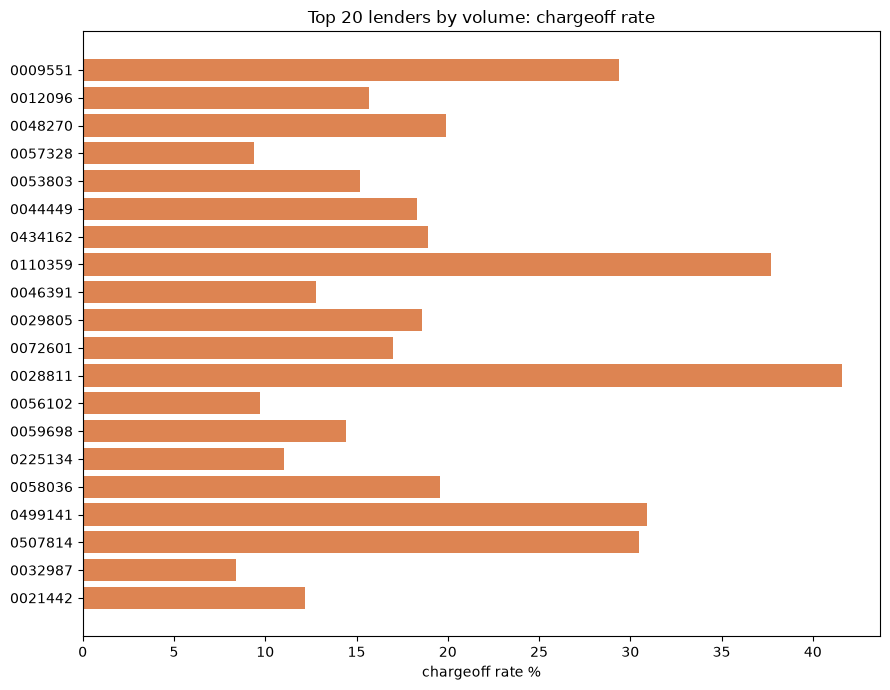

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/30_top_lenders_chgoffrate.png


In [41]:
# lender concentration (LocationID, top-N by volume)
g = resolved.groupby("LocationID")["target"]
lender_table = pd.DataFrame({"n": g.size(), "chgoff_rate_pct": (g.mean() * 100).round(1)})
lender_table = lender_table.sort_values("n", ascending=False)
top20 = lender_table.head(20)
print("top 20 LocationID by volume:")
print(top20)
total_loans = resolved["LocationID"].notna().sum()
print(f"\ntop 20 lenders = {top20['n'].sum()} loans, {top20['n'].sum()/total_loans*100:.1f}% of all resolved loans")
print(f"total distinct lenders: {resolved['LocationID'].nunique()}")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top20.index.astype(str), top20["chgoff_rate_pct"], color="#DD8452")
ax.set_xlabel("chargeoff rate %")
ax.set_title("Top 20 lenders by volume: chargeoff rate")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(f"{OUT}/30_top_lenders_chgoffrate.png", dpi=150)
plt.show()
print(f"saved {OUT}/30_top_lenders_chgoffrate.png")

## term=0 cross-checked against lender, geography, collateral, revolver status


top 20 lenders: chargeoff rate, term=0 rate, avg loan size, avg guarantee %:
                n  chgoff_rate_pct  term_zero_pct  n_term_zero  avg_GrossApproval  avg_guarantee_pct
LocationID                                                                                          
0009551     72630             29.4           0.17          124            55211.0               51.1
0012096     70895             15.7           0.14          101           238523.0               61.4
0048270     69280             19.9           0.11           78           121410.0               53.0
0057328     49642              9.4           0.06           32           205448.0               58.7
0053803     49557             15.2           0.08           41           149974.0               56.9
0044449     40499             18.3           0.17           70           160748.0               57.3
0434162     39293             18.9           0.15           57            51198.0               51.0
0110359     33

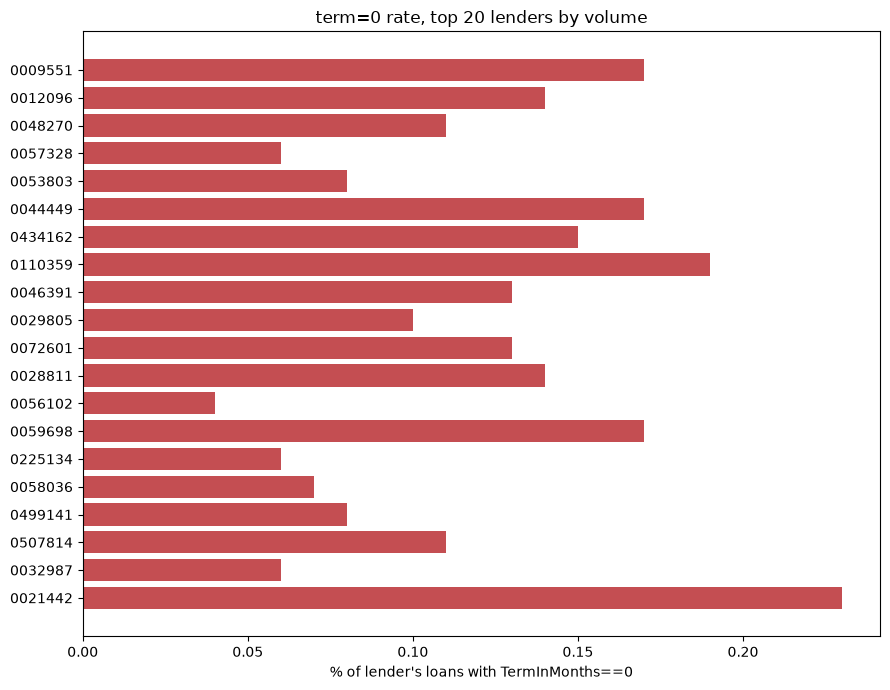

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/31_termzero_by_lender.png

lenders with the most term=0 loans (min 30 total loans):
                n  chgoff_rate_pct  term_zero_pct  n_term_zero  avg_GrossApproval  avg_guarantee_pct
LocationID                                                                                          
0009551     72630             29.4           0.17          124            55211.0               51.1
0012096     70895             15.7           0.14          101           238523.0               61.4
0048270     69280             19.9           0.11           78           121410.0               53.0
0044449     40499             18.3           0.17           70           160748.0               57.3
0110359     33356             37.7           0.19           65           197813.0               78.1
0434162     39293             18.9           0.15           57            51198.0               51.0
0053803     49557         

In [42]:
resolved["guarantee_pct"] = resolved["SBAGuaranteedApproval"] / resolved["GrossApproval"] * 100
g = resolved.groupby("LocationID")
lender_table2 = pd.DataFrame({
    "n": g.size(),
    "chgoff_rate_pct": (g["target"].mean() * 100).round(1),
    "term_zero_pct": (g["is_term_zero"].mean() * 100).round(2),
    "n_term_zero": g["is_term_zero"].sum(),
    "avg_GrossApproval": g["GrossApproval"].mean().round(0),
    "avg_guarantee_pct": g["guarantee_pct"].mean().round(1),
}).sort_values("n", ascending=False)
top20_tz = lender_table2.head(20)
print("top 20 lenders: chargeoff rate, term=0 rate, avg loan size, avg guarantee %:")
print(top20_tz.to_string())

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top20_tz.index.astype(str), top20_tz["term_zero_pct"], color="#C44E52")
ax.set_xlabel("% of lender's loans with TermInMonths==0")
ax.set_title("term=0 rate, top 20 lenders by volume")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(f"{OUT}/31_termzero_by_lender.png", dpi=150)
plt.show()
print(f"saved {OUT}/31_termzero_by_lender.png")

by_termzero_count = lender_table2[lender_table2["n"] >= 30].sort_values("n_term_zero", ascending=False).head(20)
print("\nlenders with the most term=0 loans (min 30 total loans):")
print(by_termzero_count.to_string())

term=0 rate by geography risk tier:
           term_zero_pct  n_term_zero  n_total
risk_tier                                     
A                   0.08          153   186776
B                   0.10          274   278674
C                   0.10          286   278010
D                   0.12          425   364110


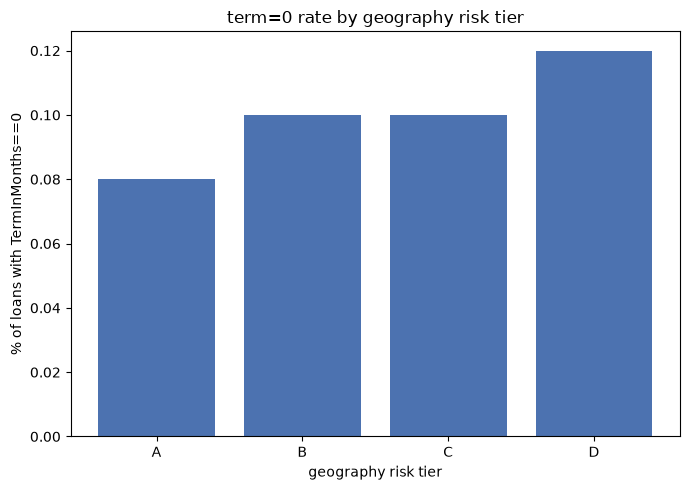

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/32_termzero_by_geotier.png


In [43]:
# term=0 rate by geography tier
resolved_geo = resolved.merge(geo[["risk_tier"]], left_on="zip3", right_index=True, how="left")

geo_termzero = resolved_geo.groupby("risk_tier", observed=True)["is_term_zero"].agg(["mean", "sum", "size"])
geo_termzero.columns = ["term_zero_pct", "n_term_zero", "n_total"]
geo_termzero["term_zero_pct"] = (geo_termzero["term_zero_pct"] * 100).round(2)
print("term=0 rate by geography risk tier:")
print(geo_termzero)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(geo_termzero.index.astype(str), geo_termzero["term_zero_pct"], color="#4C72B0")
ax.set_xlabel("geography risk tier")
ax.set_ylabel("% of loans with TermInMonths==0")
ax.set_title("term=0 rate by geography risk tier")
fig.tight_layout()
fig.savefig(f"{OUT}/32_termzero_by_geotier.png", dpi=150)
plt.show()
print(f"saved {OUT}/32_termzero_by_geotier.png")

chargeoff rate: term=0 x CollateralInd:
                            chgoff_rate       n
is_term_zero CollateralInd                     
False        N                     19.9  653827
             Y                     11.9  453096
True         N                     75.2     803
             Y                     81.0     336

chargeoff rate: term=0 x RevolverStatus:
                             chgoff_rate       n
is_term_zero RevolverStatus                     
False        N                      16.1  767567
             Y                      17.9  339356
True         N                      73.6     656
             Y                      81.4     483


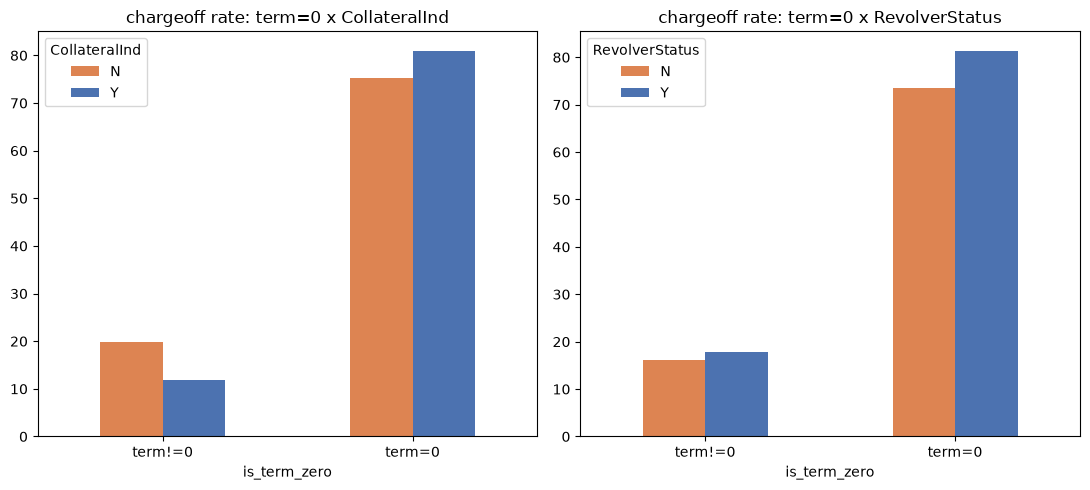

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/33_termzero_x_collateral_revolver.png


In [44]:
# term=0 chargeoff rate x CollateralInd, x RevolverStatus
collat = resolved.groupby(["is_term_zero", "CollateralInd"])["target"].agg(["mean", "size"])
collat.columns = ["chgoff_rate", "n"]
collat["chgoff_rate"] = (collat["chgoff_rate"] * 100).round(1)
print("chargeoff rate: term=0 x CollateralInd:")
print(collat)

revolv = resolved.groupby(["is_term_zero", "RevolverStatus"])["target"].agg(["mean", "size"])
revolv.columns = ["chgoff_rate", "n"]
revolv["chgoff_rate"] = (revolv["chgoff_rate"] * 100).round(1)
print("\nchargeoff rate: term=0 x RevolverStatus:")
print(revolv)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
collat.unstack("CollateralInd")["chgoff_rate"].plot(kind="bar", ax=axes[0], color=["#DD8452", "#4C72B0"])
axes[0].set_title("chargeoff rate: term=0 x CollateralInd")
axes[0].set_xticklabels(["term!=0", "term=0"], rotation=0)
revolv.unstack("RevolverStatus")["chgoff_rate"].plot(kind="bar", ax=axes[1], color=["#DD8452", "#4C72B0"])
axes[1].set_title("chargeoff rate: term=0 x RevolverStatus")
axes[1].set_xticklabels(["term!=0", "term=0"], rotation=0)
fig.tight_layout()
fig.savefig(f"{OUT}/33_termzero_x_collateral_revolver.png", dpi=150)
plt.show()
print(f"saved {OUT}/33_termzero_x_collateral_revolver.png")

## term=0: how do they actually resolve, and when?
Breaks down CHGOFF and PIF outcomes by resolution year, sector, and Fixed/Variable -- and directly
tests the leakage hypothesis (does term=0 correlate with unusually FAST chargeoffs, suggesting the
term field gets zeroed as a side effect of default rather than being an independent
origination-time value). Run per file (not pooled), same as the original script.


==================== 2000_2009: TermInMonths==0, n=909 ====================
LoanStatus
CHGOFF    703
PIF       205
EXEMPT      1
Name: count, dtype: Int64

term=0 CHGOFF: n=703, MonthsToChargeoff describe:
count    703.0
mean      80.8
std       35.8
min       12.8
10%       35.9
25%       57.0
50%       85.2
75%       94.7
90%      125.4
max      226.0
Name: MonthsToChargeoff, dtype: float64

term=0 PIF: n=205, MonthsToPIF describe:
count    205.0
mean     142.4
std       49.2
min       26.2
10%       91.6
25%      107.2
50%      130.5
75%      170.7
90%      218.2
max      303.1
Name: MonthsToPIF, dtype: float64

CHGOFF resolution year x FixedorVariableInterestInd:
FixedorVariableInterestInd  F  V
resolution_year                 
2010                        0  2
2011                        0  1
2013                        1  1
2014                        0  4
2015                        1  3
2016                        1  4
2017                        0  5
2018                      

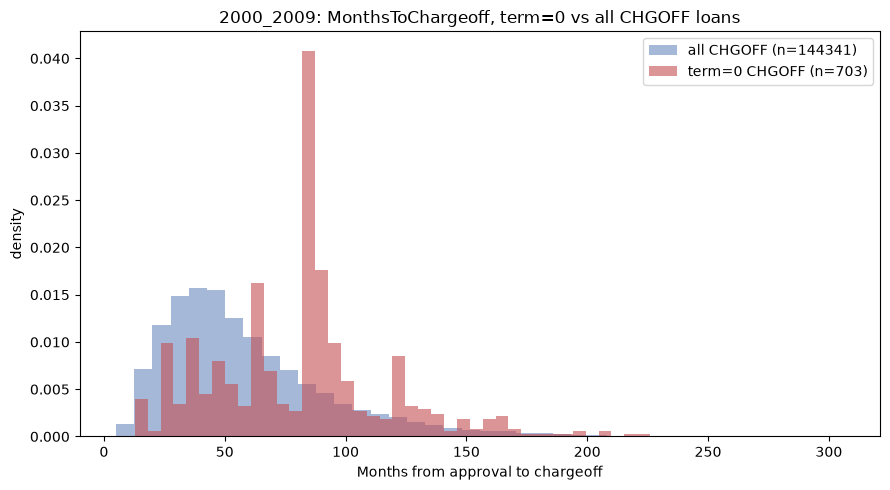

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/28_term_zero_timing_2000_2009.png
FranchiseCode: nunique changed 5074 -> 5025 after whitespace/case normalization (hidden duplicate categories collapsed)

==================== 2010_2019: TermInMonths==0, n=229 ====================
LoanStatus
CHGOFF    165
PIF        57
EXEMPT      6
CANCLD      1
Name: count, dtype: Int64

term=0 CHGOFF: n=165, MonthsToChargeoff describe:
count    165.0
mean      82.3
std       27.5
min       17.6
10%       48.6
25%       62.2
50%       84.7
75%       92.9
90%      122.0
max      150.6
Name: MonthsToChargeoff, dtype: float64

term=0 PIF: n=57, MonthsToPIF describe:
count     57.0
mean     110.0
std       29.4
min       31.2
10%       79.1
25%       94.0
50%      104.2
75%      125.6
90%      142.7
max      185.7
Name: MonthsToPIF, dtype: float64

CHGOFF resolution year x FixedorVariableInterestInd:
FixedorVariableInterestInd  F   V
resolution_year                  
2013  

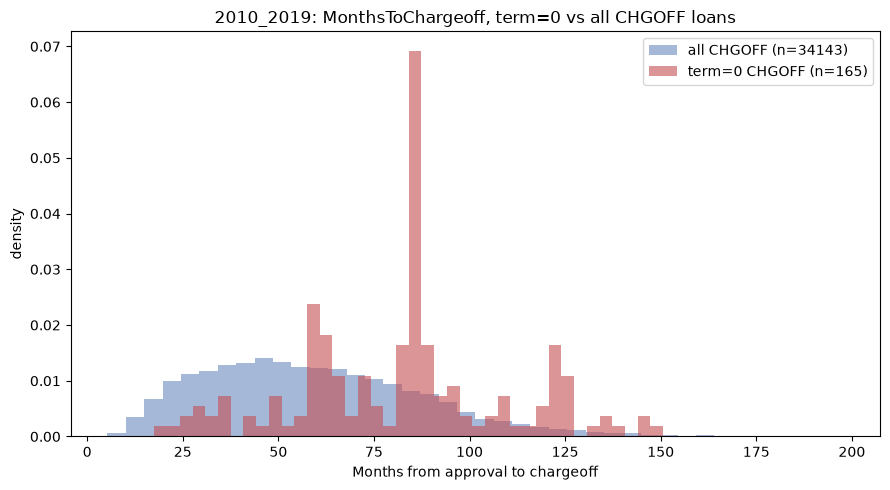

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/28_term_zero_timing_2010_2019.png
FranchiseCode: nunique changed 3691 -> 3598 after whitespace/case normalization (hidden duplicate categories collapsed)

==================== 2020_Curr: TermInMonths==0, n=11 ====================
LoanStatus
CHGOFF    8
EXEMPT    2
PIF       1
Name: count, dtype: Int64

term=0 CHGOFF: n=8, MonthsToChargeoff describe:
count     8.0
mean     45.0
std      17.6
min      24.0
10%      24.4
25%      33.2
50%      41.1
75%      63.3
90%      64.6
max      66.5
Name: MonthsToChargeoff, dtype: float64

term=0 PIF: n=1, MonthsToPIF describe:
count     1.0
mean     46.7
std       NaN
min      46.7
10%      46.7
25%      46.7
50%      46.7
75%      46.7
90%      46.7
max      46.7
Name: MonthsToPIF, dtype: float64

CHGOFF resolution year x FixedorVariableInterestInd:
FixedorVariableInterestInd  F  V
resolution_year                 
2021                        0  1
2023               

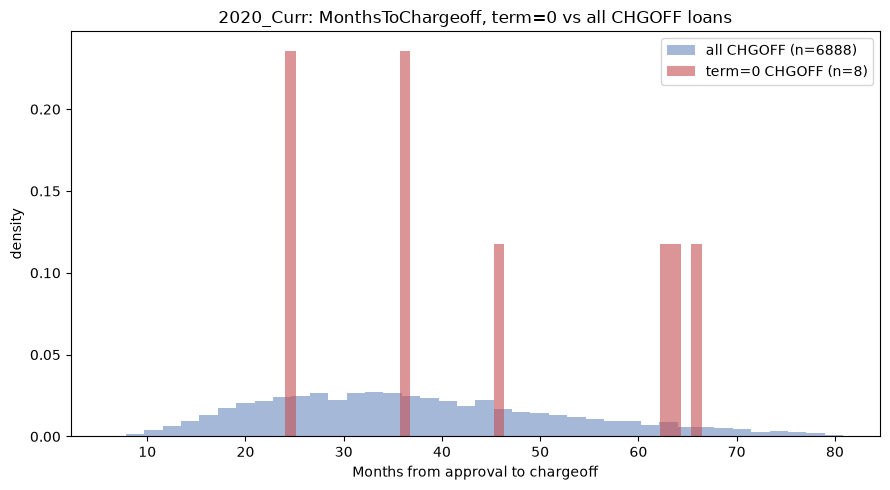

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/28_term_zero_timing_2020_Curr.png


In [45]:
def analyze(name):
    df = load_clean_sector_df(name)
    tz = df[df["TermInMonths"] == 0].copy()
    print(f"\n{'='*20} {name}: TermInMonths==0, n={len(tz)} {'='*20}")
    print(tz["LoanStatus"].value_counts())

    chgoff = tz[tz["LoanStatus"] == "CHGOFF"].copy()
    pif = tz[tz["LoanStatus"] == "PIF"].copy()

    chgoff["MonthsToChargeoff"] = (chgoff["ChargeOffDate"] - chgoff["ApprovalDate"]).dt.days / 30.44
    pif["MonthsToPIF"] = (pif["PaidInFullDate"] - pif["ApprovalDate"]).dt.days / 30.44

    print(f"\nterm=0 CHGOFF: n={len(chgoff)}, MonthsToChargeoff describe:")
    print(chgoff["MonthsToChargeoff"].describe(percentiles=[.1, .25, .5, .75, .9]).round(1))

    print(f"\nterm=0 PIF: n={len(pif)}, MonthsToPIF describe:")
    print(pif["MonthsToPIF"].describe(percentiles=[.1, .25, .5, .75, .9]).round(1))

    chgoff["resolution_year"] = chgoff["ChargeOffDate"].dt.year
    pif["resolution_year"] = pif["PaidInFullDate"].dt.year
    print("\nCHGOFF resolution year x FixedorVariableInterestInd:")
    print(pd.crosstab(chgoff["resolution_year"], chgoff["FixedorVariableInterestInd"]))
    print("\nPIF resolution year x FixedorVariableInterestInd:")
    print(pd.crosstab(pif["resolution_year"], pif["FixedorVariableInterestInd"]))

    print("\nterm=0 by sector (CHGOFF vs PIF counts):")
    print(pd.crosstab(tz["NaicsSectorName"], tz["LoanStatus"]))

    all_chgoff = df[df["LoanStatus"] == "CHGOFF"].copy()
    all_chgoff["MonthsToChargeoff"] = (all_chgoff["ChargeOffDate"] - all_chgoff["ApprovalDate"]).dt.days / 30.44

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(all_chgoff["MonthsToChargeoff"].dropna(), bins=40, alpha=0.5, density=True,
            label=f"all CHGOFF (n={all_chgoff['MonthsToChargeoff'].notna().sum()})", color="#4C72B0")
    ax.hist(chgoff["MonthsToChargeoff"].dropna(), bins=40, alpha=0.6, density=True,
            label=f"term=0 CHGOFF (n={chgoff['MonthsToChargeoff'].notna().sum()})", color="#C44E52")
    ax.set_xlabel("Months from approval to chargeoff")
    ax.set_ylabel("density")
    ax.set_title(f"{name}: MonthsToChargeoff, term=0 vs all CHGOFF loans")
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"{OUT}/28_term_zero_timing_{name}.png", dpi=150)
    plt.show()
    print(f"saved {OUT}/28_term_zero_timing_{name}.png")


for name in ORDER:
    analyze(name)

## What this notebook tells us

- **Rate and term aren't redundant** -- both carry independent chargeoff-rate signal (see the
  term x rate heatmap), so term shouldn't be dropped just because rate is present.
- **Fixed/variable and RevolverStatus** each show a real split in chargeoff rate, loan size, and
  collateral posture -- candidates for the modeling feature set.
- **Geography and lender concentration** are real but uneven: most volume sits with a small number
  of top lenders, and risk tiers vary meaningfully by zip-3 once there's enough volume to trust the
  rate.
- **term=0 is still an open question.** The cross-checks here rule out lender, geography, and
  RevolverStatus as the explanation, and flag a modest CollateralInd reversal not treated as
  conclusive. The one clear signal is that term=0 loans are smaller (median $50K vs $80K) --
  everything else is inconclusive. This stays an open item for feature engineering, not resolved
  here.